In [1]:
"""
Created By    : Jared W. Marquis
Creation Date : 01 August 2022
Course        : ATSC 528 - Atmospheric Data Analysis
Assignment    : #02 - Successive Corrections

Purpose:
Script to take sparse upper air observations and analyze them on a
polar stereographic map projection using successive corrections.
[PUT MORE INFORMATION HERE - I.E., WHAT SPECIFIC THING IS BEING DONE]

"""
__author__    = "Jared W. Marquis"
__contact__   = "jared.marquis@und.edu"
__Student_Name__ = "Austin Portner"

In [2]:
### Import Required Modules (shouldn't need to change) ###
import numpy as np                 #numpy for math
import matplotlib.pyplot as plt    #matplotlib for plotting
import cartopy.crs as ccrs         #cartopy for plotting on map
import cartopy.feature as cfeature #cartopy basic shapefiles

In [3]:
### Read in observations ###
path = 'C:/Users/austi/Desktop/AtSc_Masters_Classes/AtSc_528/Function_Fitting/'
file = 'RAOBs_201903131200.txt'
#path+file

In [4]:
### Set up analysis map with a 21x27 rectangular grid of points ###
# From hw2
lats, lons, hgts = [], [], []

with open(path+file, 'r') as f:
    for line in f:
        parts = line.strip().split(',')
        if len(parts) >=4:
            try:
                lat = float(parts[1])
                lon = float(parts[2])
                hgt = float(parts[3])
                # append valid observation data
                if not np.isnan(hgt):
                    lats.append(lat)
                    lons.append(lon)
                    hgts.append(hgt)
            except ValueError:
                continue

#Conversion to np arrays
obs_lat = np.array(lats)
obs_lon = np.array(lons)
obs_hgt = np.array(hgts)

# Now to setip 21x27 analysis grid
y, x = 27, 21
dx, dy = 1.27, 1.27 #in cm
x0, y0 = 25.0, -15.5 #in cm

# Now to generate 1D vectors and 2D meshgrid
grid_x_1d = x0 + np.arange(x) * dx
grid_y_1d = y0 + np.arange(y) * dy

grid_x_map, grid_y_map = np.meshgrid(grid_x_1d, grid_y_1d, indexing = 'ij')

In [5]:
### convert obs lat/long to x,y ###
# From hw2
lambda_0 = -100.0
phi_0 = 60.0
rho = 6371229.0 
m = 1 / 15000000
R = rho * 100.0 * m

# Angles from lat/lon to radians
lat_rad = np.radians(obs_lat)
lon_rad = np.radians(obs_lon)
lambda_0_rad = np.radians(lambda_0)
phi_0_rad = np.radians(phi_0)

#conversion to cartesian coordinates in cm
sigma_obs = (1.0 + np.sin(phi_0_rad)) / (1.0 + np.sin(lat_rad))
obs_x = R * sigma_obs * np.cos(lat_rad) * np.cos(lon_rad - lambda_0_rad)
obs_y = R * sigma_obs * np.cos(lat_rad) * np.sin(lon_rad - lambda_0_rad)

In [6]:
# now to calculate d_min and define radius of influence

num_obs = len(obs_x)
nearest_dists = []

for i in range(num_obs):
    # computes distances to other grids from grid i
    dists = np.sqrt((obs_x - obs_x[i])**2 + (obs_y - obs_y[i])**2)
    dists[i] = np.inf  # this excludes distance to self
    nearest_dists.append(np.min(dists))

d_min = np.mean(nearest_dists)

#sanity check
#print(f"d_min = {d_min:.4f} cm")

In [7]:
### Create function for Cressman Analysis ###
def cressman(target_x, target_y, source_x, source_y, source_vals, R, background_vals=None):
    """
Performs analysis using Cressman weighting function.
    
    Parameters:
    - target_x, target_y: Coordinates of target points to grid
    - source_x, source_y: Coordinates of observation locations
    - source_vals: Values at observation locations
    - R: Radius of influence for each point
    - background_vals: previous pass values
    
    Returns:
    - analyzed_vals: analyzed values matching shape of coordinates
    """

    target_shape = target_x.shape
    tx = target_x.flatten()
    ty = target_y.flatten()
    analyzed_vals = np.full(tx.shape, np.nan)

    for i in range(len(tx)):
        # Distance from pt i to all obs
        d_ik = np.sqrt((source_x - tx[i])**2 + (source_y - ty[i])**2)
        
        # filter within radius of influence
        valid_mask = (d_ik <= R) & (~np.isnan(source_vals))

        if not np.any(valid_mask):
            # This statement keeps background values
            if background_vals is not None:
                analyzed_vals[i] = background_vals.flatten()[i]
            continue
            
        d_sub = d_ik[valid_mask]
        v_sub = source_vals[valid_mask]

        # weight function
        weights = (R**2 - d_sub**2) / (R**2 + d_sub**2)
        
        weight_sum = np.sum(weights)
        if weight_sum == 0:
            continue
            
        val_corrected = np.sum(weights * v_sub) / weight_sum
        
        if background_vals is not None:
            analyzed_vals[i] = background_vals.flatten()[i] + val_corrected
        else:
            analyzed_vals[i] = val_corrected
    
    return analyzed_vals.reshape(target_shape)

In [8]:
### Create function for bilinear interpolation ###
# This was terrible to figure out but we got it
def bilinear_interpolation(grid_x_1d, grid_y_1d, grid_field, ox, oy):
    """
    Performs bilinear interpolation of grid at point (ox, oy)
    returns NaN if pt is outside grid domain
    """
    if ox < grid_x_1d[0] or ox > grid_x_1d[-1] or oy < grid_y_1d[0] or oy > grid_y_1d[-1]:
        return np.nan
        
    i = np.searchsorted(grid_x_1d, ox) - 1
    j = np.searchsorted(grid_y_1d, oy) - 1
    
    if i >= len(grid_x_1d) - 1: i = len(grid_x_1d) - 2
    if j >= len(grid_y_1d) - 1: j = len(grid_y_1d) - 2
    if i < 0: i = 0
    if j < 0: j = 0
    
    x1, x2 = grid_x_1d[i], grid_x_1d[i+1]
    y1, y2 = grid_y_1d[j], grid_y_1d[j+1]
    
    Q11 = grid_field[i, j]
    Q21 = grid_field[i+1, j]
    Q12 = grid_field[i, j+1]
    Q22 = grid_field[i+1, j+1]
    
    if np.isnan(Q11) or np.isnan(Q21) or np.isnan(Q12) or np.isnan(Q22):
        return np.nan
        
    t = (ox - x1) / (x2 - x1) if x2 != x1 else 0.0
    u = (oy - y1) / (y2 - y1) if y2 != y1 else 0.0
    
    val = ((1 - t) * (1 - u) * Q11 + 
           t * (1 - u) * Q21 + 
           (1 - t) * u * Q12 + 
           t * u * Q22)
    return val

In [9]:
# Using this function for passes 2 and 3
# It basically just let's me do the pass after reinterpolating the previous pass
def estimate_obs_at_stations(grid_x_1d, grid_y_1d, grid_field, obs_x, obs_y, grid_x_map, grid_y_map, R_pass):
    est_vals = np.full(obs_x.shape, np.nan)
    grid_flat_x = grid_x_map.flatten()
    grid_flat_y = grid_y_map.flatten()
    grid_flat_vals = grid_field.flatten()
    
    for k in range(len(obs_x)):
        val = bilinear_interpolation(grid_x_1d, grid_y_1d, grid_field, obs_x[k], obs_y[k])
        if np.isnan(val):
            # Outside the domain it will use Cressman function
            d_ik = np.sqrt((grid_flat_x - obs_x[k])**2 + (grid_flat_y - obs_y[k])**2)
            valid_mask = (d_ik <= R_pass) & (~np.isnan(grid_flat_vals))
            if np.any(valid_mask):
                d_sub = d_ik[valid_mask]
                v_sub = grid_flat_vals[valid_mask]
                weights = (R_pass**2 - d_sub**2) / (R_pass**2 + d_sub**2)
                weight_sum = np.sum(weights)
                if weight_sum > 0:
                    est_vals[k] = np.sum(weights * v_sub) / weight_sum
        else:
            est_vals[k] = val
    return est_vals

In [10]:
### Perform 500mb geopotential height analyses using a Cressman weighting Function###
#Use radii of influence 4, 2.5, 1.5 *dmin
# Radii of influence for each pass calculation
R1 = 4.0 * d_min
R2 = 2.5 * d_min
R3 = 1.5 * d_min

#print(R1, R2, R3, d_min)

In [11]:
### First analysis, no successive corrections ###
grid_analysis_1 = cressman(grid_x_map, grid_y_map, obs_x, obs_y, obs_hgt, R1, background_vals = None)

In [12]:
### Next Analyses ###
# Pass 2
obs_est_1 = estimate_obs_at_stations(grid_x_1d, grid_y_1d, grid_analysis_1, obs_x, obs_y, grid_x_map, grid_y_map, R2)
residuals_1 = obs_hgt - obs_est_1

grid_analysis_2 = cressman(grid_x_map, grid_y_map, obs_x, obs_y, residuals_1, R2, background_vals=grid_analysis_1)

# Pass 3
obs_est_2 = estimate_obs_at_stations(grid_x_1d, grid_y_1d, grid_analysis_2, obs_x, obs_y, grid_x_map, grid_y_map, R3)
residuals_2 = obs_hgt - obs_est_2

grid_analysis_3 = cressman(grid_x_map, grid_y_map, obs_x, obs_y, residuals_2, R3, background_vals=grid_analysis_2)

In [13]:
### Calculate Analysis Differences
# Difference between passes
diff_2_1 = grid_analysis_2 - grid_analysis_1
diff_3_1 = grid_analysis_3 - grid_analysis_1
diff_3_2 = grid_analysis_3 - grid_analysis_2

# Root mean square differences with obs for each pass
obs_est_pass1 = estimate_obs_at_stations(grid_x_1d, grid_y_1d, grid_analysis_1, obs_x, obs_y, grid_x_map, grid_y_map, R1)
obs_est_pass2 = estimate_obs_at_stations(grid_x_1d, grid_y_1d, grid_analysis_2, obs_x, obs_y, grid_x_map, grid_y_map, R2)
obs_est_pass3 = estimate_obs_at_stations(grid_x_1d, grid_y_1d, grid_analysis_3, obs_x, obs_y, grid_x_map, grid_y_map, R3)

# Function used for rms differences
def compute_rms(obs, est):
    valid = ~np.isnan(obs) & ~np.isnan(est)
    return np.sqrt(np.mean((obs[valid] - est[valid])**2))

rms_1 = compute_rms(obs_hgt, obs_est_pass1)
rms_2 = compute_rms(obs_hgt, obs_est_pass2)
rms_3 = compute_rms(obs_hgt, obs_est_pass3)

#print(rms_1, rms_2, rms_3)

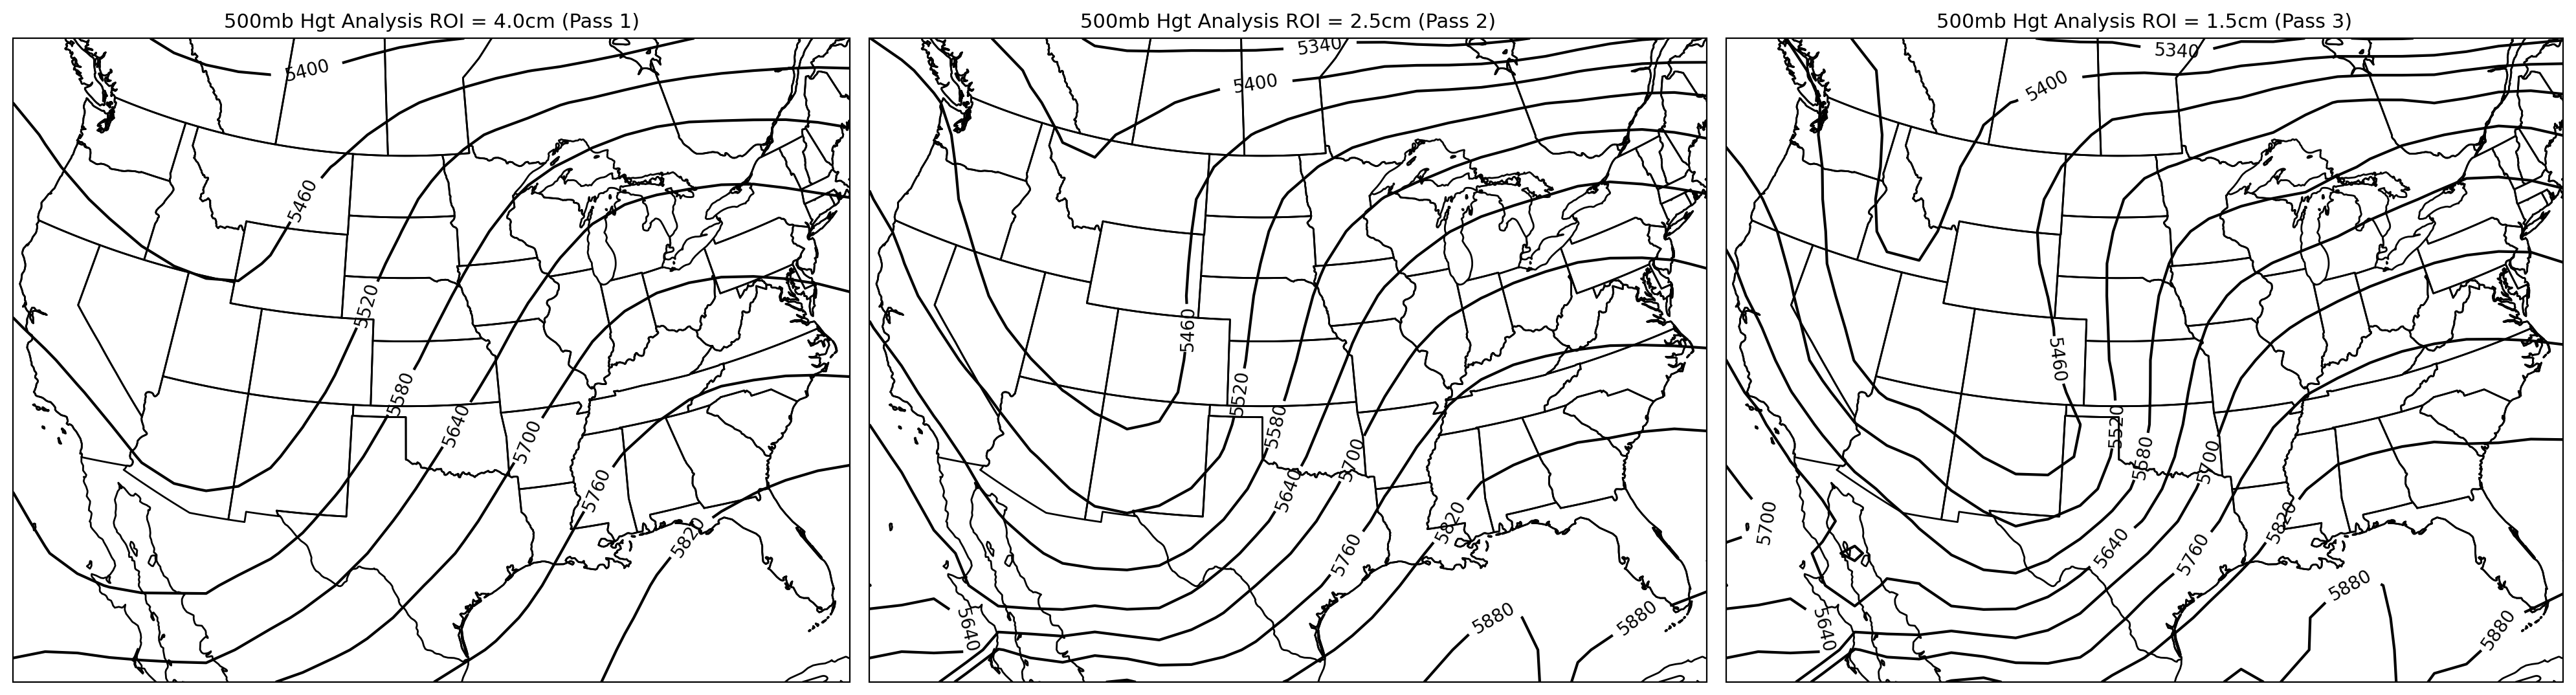

In [14]:
## Analysis Plots ##
# Each pass in a for loop

globe = ccrs.Globe(ellipse=None, semimajor_axis=rho, semiminor_axis=rho)
proj = ccrs.Stereographic(central_longitude=lambda_0, central_latitude=90, true_scale_latitude=phi_0, globe=globe)

fig, axes = plt.subplots(1, 3, figsize=(20, 7), dpi=200, subplot_kw={'projection': proj})

analyses = [grid_analysis_1, grid_analysis_2, grid_analysis_3]
titles = [
    '500mb Hgt Analysis ROI = 4.0cm (Pass 1)', 
    '500mb Hgt Analysis ROI = 2.5cm (Pass 2)', 
    '500mb Hgt Analysis ROI = 1.5cm (Pass 3)'
]
levels = np.arange(4800, 6000, 60)

for ax, analysis, title in zip(axes, analyses, titles):
    ax.add_feature(cfeature.STATES)
    ax.add_feature(cfeature.COASTLINE)
    
    cs1 = ax.contour(grid_y_map / m / 100, -grid_x_map / m / 100, analysis, colors='k', levels=levels, transform=proj)
    ax.clabel(cs1, levels=levels, fmt='%d')
    ax.set_title(title, fontsize=11)

plt.tight_layout()
plt.savefig('500mb_hgt_all_passes.png', dpi=300, bbox_inches='tight')
plt.show()

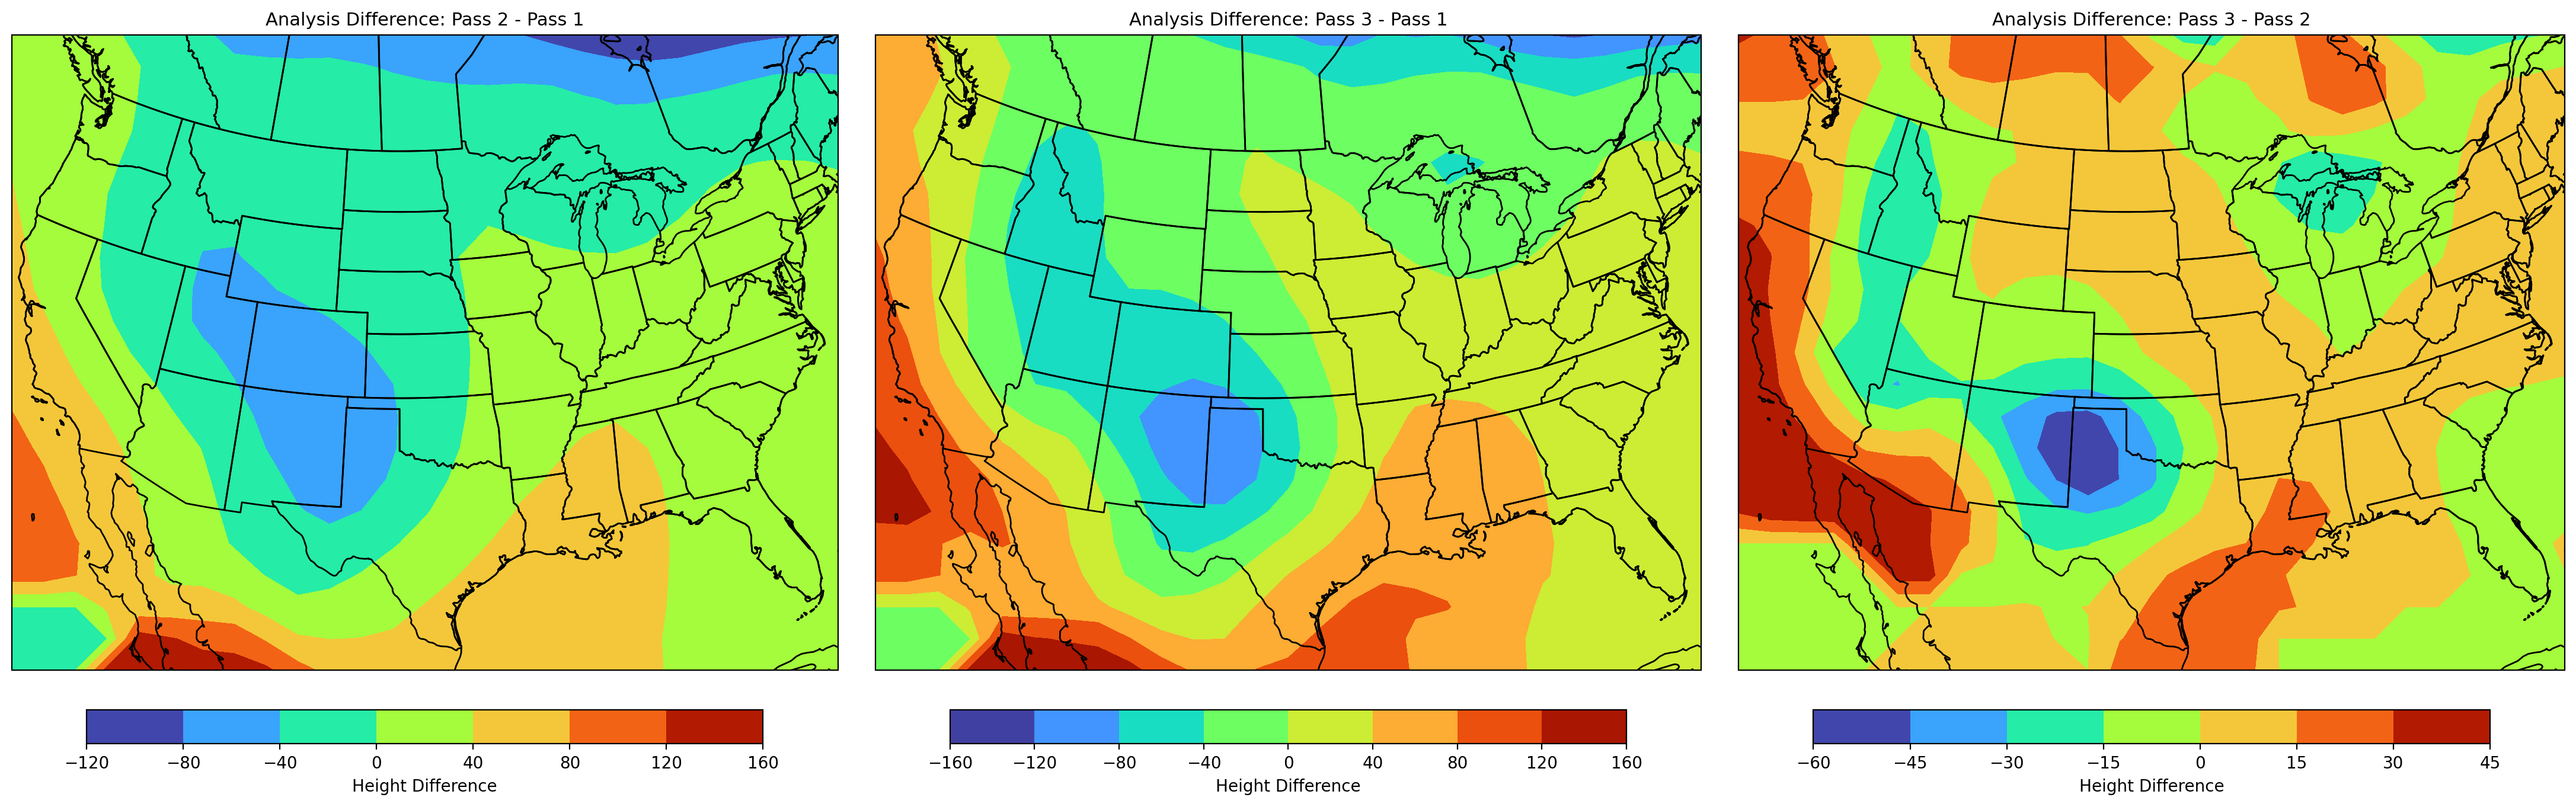

In [15]:
### Plot Analysis Differences ###
# Differences in a for loop

globe = ccrs.Globe(ellipse=None, semimajor_axis=rho, semiminor_axis=rho)
proj = ccrs.Stereographic(central_longitude=lambda_0, central_latitude=90, true_scale_latitude=phi_0, globe=globe)

fig, axes = plt.subplots(1, 3, figsize=(22, 7), dpi=200, subplot_kw={'projection': proj})

diffs = [diff_2_1, diff_3_1, diff_3_2]
titles = [
    'Analysis Difference: Pass 2 - Pass 1', 
    'Analysis Difference: Pass 3 - Pass 1', 
    'Analysis Difference: Pass 3 - Pass 2'
]

for ax, diff, title in zip(axes, diffs, titles):
    ax.add_feature(cfeature.STATES)
    ax.add_feature(cfeature.COASTLINE)
    
    cf = ax.contourf(grid_y_map / m / 100, -grid_x_map / m / 100, diff, cmap='turbo', transform=proj)
    fig.colorbar(cf, ax=ax, orientation='horizontal', pad=0.05, shrink=0.8, label='Height Difference')
    
    ax.set_title(title, fontsize=11)

plt.tight_layout()
plt.savefig('all_analysis_differences.png', dpi=300, bbox_inches='tight')
plt.show()

In [16]:
### Store the analyses in text files ###

np.savetxt('Analysis_Pass1.txt', grid_analysis_1, delimiter=',')
np.savetxt('Analysis_Pass2.txt', grid_analysis_2, delimiter=',')
np.savetxt('Analysis_Pass3.txt', grid_analysis_3, delimiter=',')

In [17]:
### Store the difference fields in text files ###
np.savetxt('Difference_Pass2_Pass1.txt', diff_2_1, delimiter=',')
np.savetxt('Difference_Pass3_Pass1.txt', diff_3_1, delimiter=',')
np.savetxt('Difference_Pass3_Pass2.txt', diff_3_2, delimiter=',')

In [18]:
### Store RMS values in text file ###
rms_data = np.array([rms_1, rms_2, rms_3])
np.savetxt('RMS_Values.txt', rms_data, delimiter=',', header='RMS Pass 1, Pass 2, Pass 3')

In [19]:
### In a separte text file (or below), answer the following questions ###
'''
1 - Describe the general features that you see in your contoured analyses.

    The features show a trough over the western United States that gets more pronounced with each pass. The 5880 contour shows up in pass 2 and 3.
    This contour goes more south with pass 3. It is not present in pass 1. The 2nd and 3rd passes have contours in the east Pacific; Gulf of California
    area. There is an area of compact contours in eastern Canada that becomes more pronounced with each pass. The contours over Mexico become more 
    compact with each pass as well.

2 - Describe the differences that you see in your contoured analyses.  
    Does one analysis seem to be smoother than the other?  If so, what would cause this?

    The difference plots show a smoother large scale pattern between the 1st and 2nd pass and the 1st and 3rd pass. This correlates well with 
    what is shown in each pass. The first analysis is more smooth than the 2nd and 3rd due to the features being less resolved. As each pass happens,
    more features become resolved. The first pass resolves the large scale features while the 2nd and 3rd pass resolve smaller scale features.

3 - What happens as you increase the number of successive correction passes?  Is this 
    desirable?  Why or why not?

    As the number of passes increase, more small scale features resolve. This can be desirable up to a certain number of passes, in this case maybe 3-4
    passes. Once you get to many passes, features that do not exist start to pop up and that is when things become undesirabel. Overall, a few passes
    may be desirable, but to many passes becomes undesirable due to features that do not exist popping up on the plots.

'''

'\n1 - Describe the general features that you see in your contoured analyses.\n\n    The features show a trough over the western United States that gets more pronounced with each pass. The 5880 contour shows up in pass 2 and 3.\n    This contour goes more south with pass 3. It is not present in pass 1. The 2nd and 3rd passes have contours in the east Pacific; Gulf of California\n    area. There is an area of compact contours in eastern Canada that becomes more pronounced with each pass. The contours over Mexico become more \n    compact with each pass as well.\n\n2 - Describe the differences that you see in your contoured analyses.  \n    Does one analysis seem to be smoother than the other?  If so, what would cause this?\n\n    The difference plots show a smoother large scale pattern between the 1st and 2nd pass and the 1st and 3rd pass. This correlates well with \n    what is shown in each pass. The first analysis is more smooth than the 2nd and 3rd due to the features being less res